In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("Iris.csv")

print(df.head())
print(df.shape)
print(df.columns)

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
(150, 6)
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')


In [3]:
X = df.drop(columns=["Id", "Species"], errors="ignore")

print(X.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data scaled successfully")

Data scaled successfully


In [5]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

print(wcss)

[600.0, 223.73200573676348, 140.96581663074699, 114.61788585776677, 91.29544474066981, 81.75658187204954, 71.31982095188795, 62.651767150319046, 55.261841196034645, 50.62316902954044]


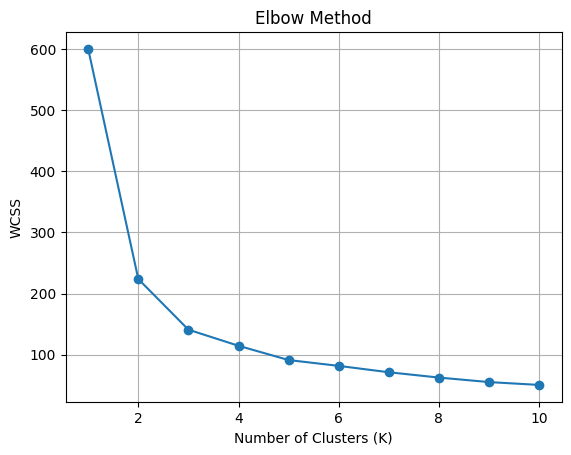

In [6]:
plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.grid(True)

plt.show()

In [7]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df.head())
print("\nCluster Counts:")
print(df["Cluster"].value_counts().sort_index())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   

   Cluster  
0        1  
1        1  
2        1  
3        1  
4        1  

Cluster Counts:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


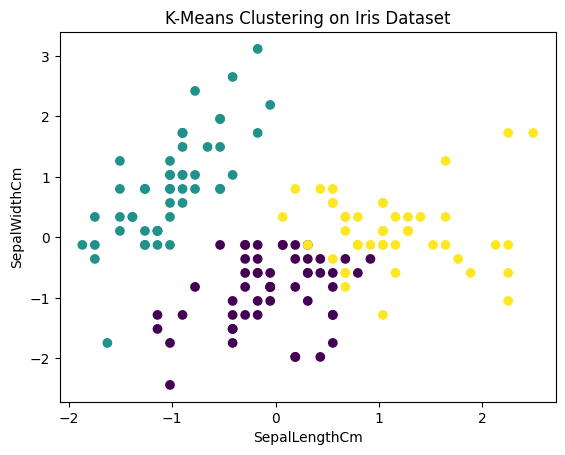

In [8]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=df["Cluster"],
    cmap="viridis"
)

plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])

plt.show()